# Home Credit Default Risk

Goal: predict whether a given data entry (representing a customer) is likely to default (= fail to make a required payment) on their loan based on a variety of customer data provide. The task is to create a machine learning model that best predicts the probability of default for each customer.

## 1. Setup


### 1.1 Importing Libraries

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

import warnings 
warnings.filterwarnings('ignore')

check if the path is correctly set

In [2]:
import os 
from pathlib import Path

current_dir = Path(os.getcwd())

train_file = current_dir/"input"/"train.csv"
test_file = current_dir/"input"/"test.csv"
sample_sub_file = current_dir/"input"/"sample_submission.csv"

if train_file.exists() and test_file.exists() and sample_sub_file.exists():
    print("All files exist and path is correctly set.")
else:
    print("Some files are missing or path is not correctly set.")

All files exist and path is correctly set.


## 2. Loadind the Data

### 2.1 Data Overview

In [3]:
train = pd.read_csv(train_file)
test = pd.read_csv(test_file)
sample_sub = pd.read_csv(sample_sub_file)

Brief overview of the data

In [4]:
# train data
print(f"train shape: {train.shape}")
train.head()

train shape: (171202, 34)


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
0,0,Cash loans,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,...,School,NaN,0.372591,NaN,-292.0,NaN,NaN,NaN,NaN,0
1,1,Cash loans,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,...,XNA,NaN,0.449567,0.553165,-617.0,0.0,0.0,0.0,1.0,0
2,2,Cash loans,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,...,Postal,NaN,0.569503,NaN,-542.0,NaN,NaN,NaN,NaN,0
3,3,Cash loans,F,0,67500.0,152820.0,8901.0,135000.0,Pensioner,Lower secondary,...,XNA,NaN,0.105235,0.767523,0.0,0.0,0.0,0.0,0.0,0
4,4,Cash loans,M,0,157500.0,271066.5,21546.0,234000.0,Commercial associate,Secondary / secondary special,...,Business Entity Type 3,0.342344,0.202490,0.669057,-1243.0,0.0,0.0,0.0,4.0,1


In [5]:
# test data
print(f"test shape: {test.shape}")
test.head()

test shape: (61500, 33)


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,REGION_RATING_CLIENT,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,171202,Cash loans,F,1,144000.0,961146.0,28233.0,688500.0,Working,Higher education,...,2,Kindergarten,NaN,0.720416,NaN,-1.0,NaN,NaN,NaN,NaN
1,171203,Cash loans,F,0,103500.0,296280.0,16069.5,225000.0,Working,Secondary / secondary special,...,2,School,NaN,0.287306,NaN,-212.0,NaN,NaN,NaN,NaN
2,171204,Cash loans,F,1,180000.0,183694.5,11236.5,139500.0,Commercial associate,Secondary / secondary special,...,3,Trade: type 7,NaN,0.352456,0.389339,-428.0,0.0,1.0,1.0,1.0
3,171205,Revolving loans,F,2,225000.0,450000.0,22500.0,450000.0,Working,Higher education,...,2,Business Entity Type 3,NaN,0.470384,0.217629,-442.0,0.0,0.0,0.0,3.0
4,171206,Cash loans,F,2,144000.0,545040.0,26640.0,450000.0,Working,Higher education,...,3,Business Entity Type 3,0.269931,0.373133,NaN,-1333.0,0.0,0.0,0.0,3.0


Excluding the TARGET column in train data and the SK_ID_CURR which represents ID number, there are 32 types of features

### 2.2 Selecting Features

1) **IMPORTANT FEATURES**

- **External Scores:** EXT_SOURCE_1, EXT_SOURCE_2, EXT_SOURCE_3 -> Represent score of birôs of external credits already normalized
- **Finantial Capacity and Contract Terms:** AMT_CREDIT, AMT_ANNUITY, AMT_INCOME_TOTAL, AMT_GOODS_PRICE, NAME_CONTRACT_TYPE, OWN_CAR_AGE -> Features to build income commitment indicators
- **Temporal Stability:** DAYS_BIRTH, DAYS_EMPLOYED, DAYS_ID_PUBLISH, DAYS_LAST_PHONE_CHANGE; -> Age and time of employment have strong negative correlation with default (older and stables clients tend to delay less)
- **Socioeconomic Profile:** NAME_EDUCATION_TYPE, CODE_GENDER, NAME_INCOME_TYPE, OCCUPATION_TYPE, REGION_RATING_CLIENT, ORGANIZATION_TYPE; -> Capture difference structures of risk between education range, occupation types and region classification where the client lives. 

This selection occurred based on archive "HomeCredit_columns_description.xlsx"




In [6]:
use_features = [
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_INCOME_TOTAL",
    "AMT_GOODS_PRICE",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED",
    "DAYS_ID_PUBLISH",
    "DAYS_LAST_PHONE_CHANGE",
    "NAME_EDUCATION_TYPE",
    "CODE_GENDER",
    "NAME_INCOME_TYPE",
    "NAME_CONTRACT_TYPE",
    "OCCUPATION_TYPE",
    "OWN_CAR_AGE",
    "ORGANIZATION_TYPE",
    "REGION_RATING_CLIENT"
]

target = train["TARGET"].values

train = train[use_features]
train["TARGET"] = target
test = test[use_features]

check the data once again

In [7]:
print(f"train_shape: {train.shape}")
print(train.columns)
train.head()

train_shape: (171202, 20)
Index(['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'AMT_CREDIT',
       'AMT_ANNUITY', 'AMT_INCOME_TOTAL', 'AMT_GOODS_PRICE', 'DAYS_BIRTH',
       'DAYS_EMPLOYED', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE',
       'NAME_EDUCATION_TYPE', 'CODE_GENDER', 'NAME_INCOME_TYPE',
       'NAME_CONTRACT_TYPE', 'OCCUPATION_TYPE', 'OWN_CAR_AGE',
       'ORGANIZATION_TYPE', 'REGION_RATING_CLIENT', 'TARGET'],
      dtype='str')


,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,AMT_CREDIT,AMT_ANNUITY,AMT_INCOME_TOTAL,AMT_GOODS_PRICE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_ID_PUBLISH,DAYS_LAST_PHONE_CHANGE,NAME_EDUCATION_TYPE,CODE_GENDER,NAME_INCOME_TYPE,NAME_CONTRACT_TYPE,OCCUPATION_TYPE,OWN_CAR_AGE,ORGANIZATION_TYPE,REGION_RATING_CLIENT,TARGET
0,NaN,0.372591,NaN,755190.0,36328.5,112500.0,675000.0,-9233,-878,-522,-292.0,Higher education,F,Working,Cash loans,Core staff,NaN,School,2,0
1,NaN,0.449567,0.553165,585000.0,16893.0,225000.0,585000.0,-20148,365243,-3436,-617.0,Secondary / secondary special,F,Pensioner,Cash loans,Other,NaN,XNA,2,0
2,NaN,0.569503,NaN,334152.0,18256.5,54000.0,270000.0,-18496,-523,-2050,-542.0,Secondary / secondary special,F,State servant,Cash loans,Core staff,NaN,Postal,2,0
3,NaN,0.105235,0.767523,152820.0,8901.0,67500.0,135000.0,-24177,365243,-3951,0.0,Lower secondary,F,Pensioner,Cash loans,Other,NaN,XNA,3,0
4,0.342344,0.202490,0.669057,271066.5,21546.0,157500.0,234000.0,-10685,-697,-3226,-1243.0,Secondary / secondary special,M,Commercial associate,Cash loans,Drivers,NaN,Business Entity Type 3,3,1


In [8]:
print(f"test_shape: {test.shape}")
print(test.columns)
test.head()

test_shape: (61500, 19)
Index(['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'AMT_CREDIT',
       'AMT_ANNUITY', 'AMT_INCOME_TOTAL', 'AMT_GOODS_PRICE', 'DAYS_BIRTH',
       'DAYS_EMPLOYED', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE',
       'NAME_EDUCATION_TYPE', 'CODE_GENDER', 'NAME_INCOME_TYPE',
       'NAME_CONTRACT_TYPE', 'OCCUPATION_TYPE', 'OWN_CAR_AGE',
       'ORGANIZATION_TYPE', 'REGION_RATING_CLIENT'],
      dtype='str')


,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,AMT_CREDIT,AMT_ANNUITY,AMT_INCOME_TOTAL,AMT_GOODS_PRICE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_ID_PUBLISH,DAYS_LAST_PHONE_CHANGE,NAME_EDUCATION_TYPE,CODE_GENDER,NAME_INCOME_TYPE,NAME_CONTRACT_TYPE,OCCUPATION_TYPE,OWN_CAR_AGE,ORGANIZATION_TYPE,REGION_RATING_CLIENT
0,NaN,0.720416,NaN,961146.0,28233.0,144000.0,688500.0,-12108,-2372,-3022,-1.0,Higher education,F,Working,Cash loans,Medicine staff,NaN,Kindergarten,2
1,NaN,0.287306,NaN,296280.0,16069.5,103500.0,225000.0,-17907,-1712,-253,-212.0,Secondary / secondary special,F,Working,Cash loans,Cleaning staff,NaN,School,2
2,NaN,0.352456,0.389339,183694.5,11236.5,180000.0,139500.0,-15221,-553,-4495,-428.0,Secondary / secondary special,F,Commercial associate,Cash loans,Other,NaN,Trade: type 7,3
3,NaN,0.470384,0.217629,450000.0,22500.0,225000.0,450000.0,-11217,-1438,-1189,-442.0,Higher education,F,Working,Revolving loans,Other,NaN,Business Entity Type 3,2
4,0.269931,0.373133,NaN,545040.0,26640.0,144000.0,450000.0,-11415,-2362,-1728,-1333.0,Higher education,F,Working,Cash loans,Other,14.0,Business Entity Type 3,3


## 3. Visualizing and Understanding the Data

Section to visualizing and analyzing, to deepen the understanding of data distribution, missing values, outliers, correlations, and etc. The results of the analysis obtained at this stage will be useful for preprocessing, feature creation, and selection of machine learning models, which are all imoortant to building modelos with better prediction ability.

### 3.1 Checking Missing Values

In [9]:
train.isnull().sum()

EXT_SOURCE_1              118928
EXT_SOURCE_2                 369
EXT_SOURCE_3               54586
AMT_CREDIT                     0
AMT_ANNUITY                    0
AMT_INCOME_TOTAL               0
AMT_GOODS_PRICE                0
DAYS_BIRTH                     0
DAYS_EMPLOYED                  0
DAYS_ID_PUBLISH                0
DAYS_LAST_PHONE_CHANGE         0
NAME_EDUCATION_TYPE            0
CODE_GENDER                    0
NAME_INCOME_TYPE               0
NAME_CONTRACT_TYPE             0
OCCUPATION_TYPE                0
OWN_CAR_AGE               112992
ORGANIZATION_TYPE              0
REGION_RATING_CLIENT           0
TARGET                         0
dtype: int64

In [10]:
test.isnull().sum()

EXT_SOURCE_1              42912
EXT_SOURCE_2                130
EXT_SOURCE_3              19690
AMT_CREDIT                    0
AMT_ANNUITY                   0
AMT_INCOME_TOTAL              0
AMT_GOODS_PRICE               0
DAYS_BIRTH                    0
DAYS_EMPLOYED                 0
DAYS_ID_PUBLISH               0
DAYS_LAST_PHONE_CHANGE        0
NAME_EDUCATION_TYPE           0
CODE_GENDER                   0
NAME_INCOME_TYPE              0
NAME_CONTRACT_TYPE            0
OCCUPATION_TYPE               0
OWN_CAR_AGE               40909
ORGANIZATION_TYPE             0
REGION_RATING_CLIENT          0
dtype: int64

Firstly, **OWN_CAR_AGE** with null values indicates that the person haven't a car. Therefore, **EXT_SOURCEs** with null values indicates an important information (Missing Not At Random - MNAR): the person didn't present credit bureau change the probability of default, because thin-file clients (with little information for credit history) presents an curious behaviour: fee of default upper than clients with good credit history, and lower than clients with bad credit history. So, has many reasons theses informations are equal "null", and it's important too.

In this project, i don't will to do a treatment in null values, and it's not an problem to machine learning models because i'll use Ensemble Learning techniques (such Random Forest, LGBM, XGBoost and Catboost).

### 3.2 Visualization and analysis of each feature

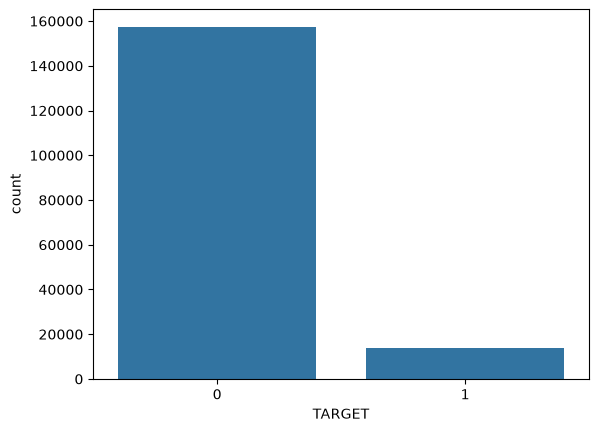

In [11]:
sns.countplot(data = train, x = "TARGET")
plt.show()

The distribution of the objective variable is highly skewed (Unbalanced data). 

In [12]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 171202 entries, 0 to 171201
Data columns (total 20 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   EXT_SOURCE_1            52274 non-null   float64
 1   EXT_SOURCE_2            170833 non-null  float64
 2   EXT_SOURCE_3            116616 non-null  float64
 3   AMT_CREDIT              171202 non-null  float64
 4   AMT_ANNUITY             171202 non-null  float64
 5   AMT_INCOME_TOTAL        171202 non-null  float64
 6   AMT_GOODS_PRICE         171202 non-null  float64
 7   DAYS_BIRTH              171202 non-null  int64  
 8   DAYS_EMPLOYED           171202 non-null  int64  
 9   DAYS_ID_PUBLISH         171202 non-null  int64  
 10  DAYS_LAST_PHONE_CHANGE  171202 non-null  float64
 11  NAME_EDUCATION_TYPE     171202 non-null  str    
 12  CODE_GENDER             171202 non-null  str    
 13  NAME_INCOME_TYPE        171202 non-null  str    
 14  NAME_CONTRACT_TYPE      171202 

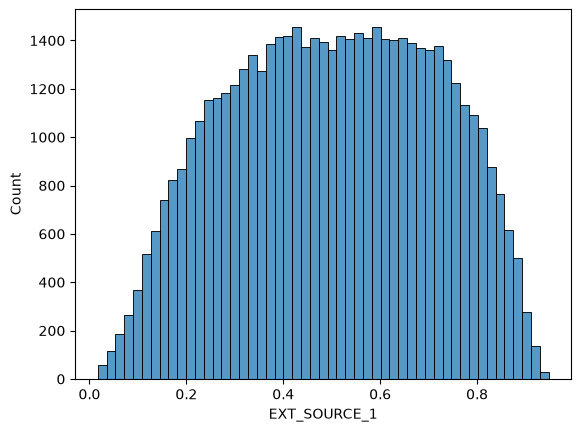

In [13]:
sns.histplot(data = train, x = "EXT_SOURCE_1")
plt.show()

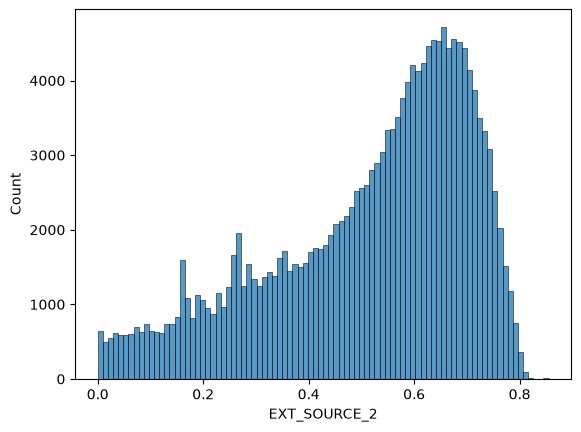

In [14]:
sns.histplot(data = train, x = "EXT_SOURCE_2")
plt.show()

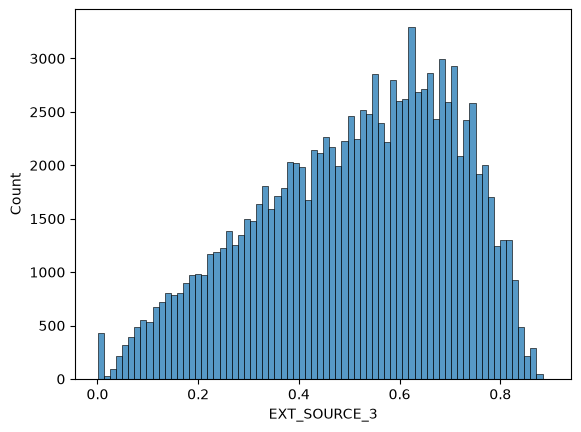

In [15]:
sns.histplot(data = train, x = "EXT_SOURCE_3")
plt.show()

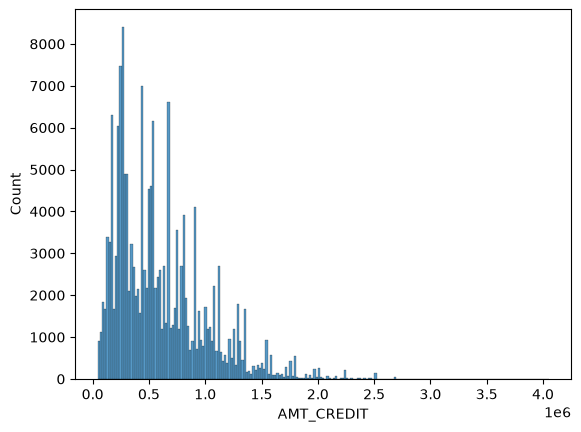

In [16]:
sns.histplot(data = train, x = "AMT_CREDIT")
plt.show()

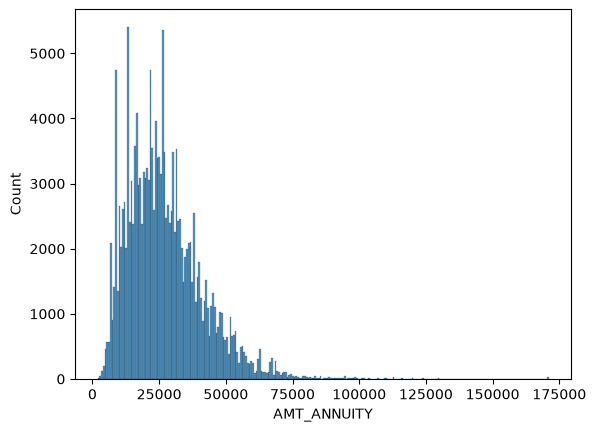

In [17]:
sns.histplot(data = train, x = "AMT_ANNUITY")
plt.show()

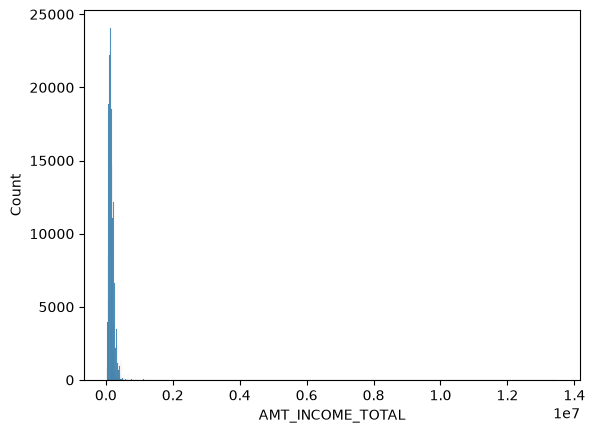

In [18]:
sns.histplot(data = train, x = "AMT_INCOME_TOTAL")
plt.show()

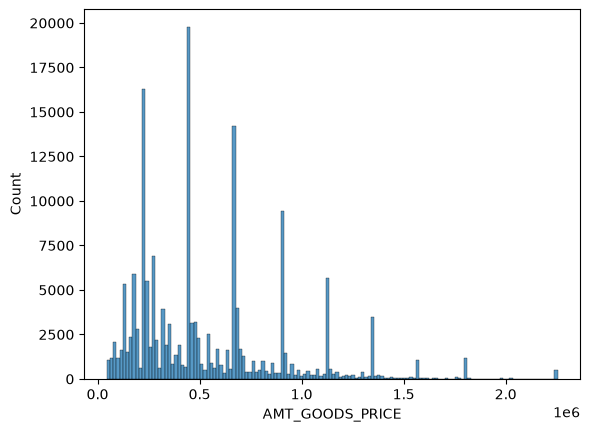

In [19]:
sns.histplot(data = train, x = "AMT_GOODS_PRICE")
plt.show()

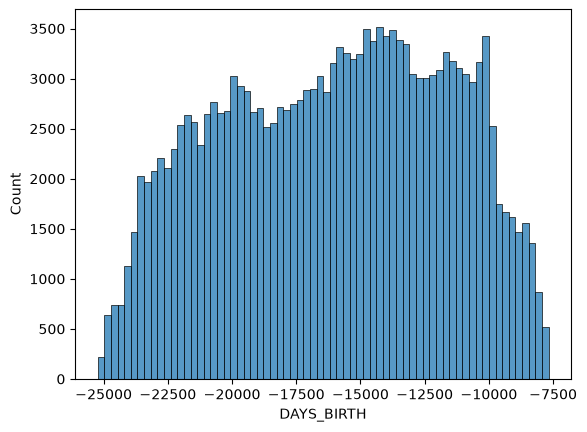

In [20]:
sns.histplot(data = train, x = "DAYS_BIRTH")
plt.show()

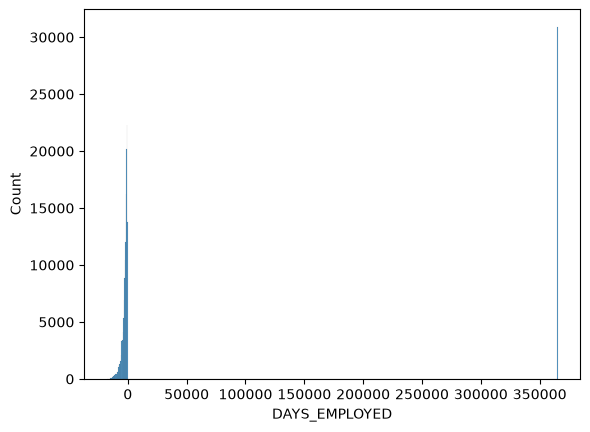

In [21]:
sns.histplot(data = train, x = "DAYS_EMPLOYED")
plt.show()

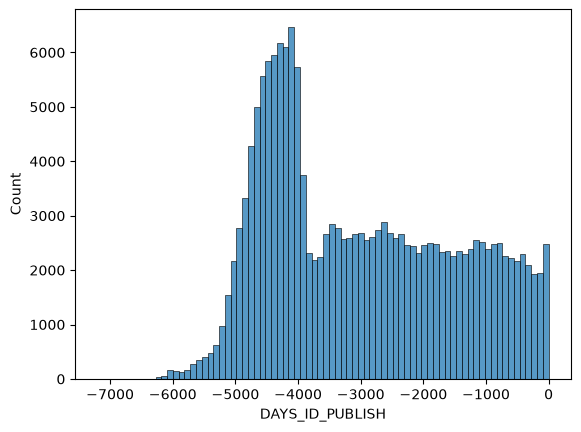

In [22]:
sns.histplot(data = train, x = "DAYS_ID_PUBLISH")
plt.show()

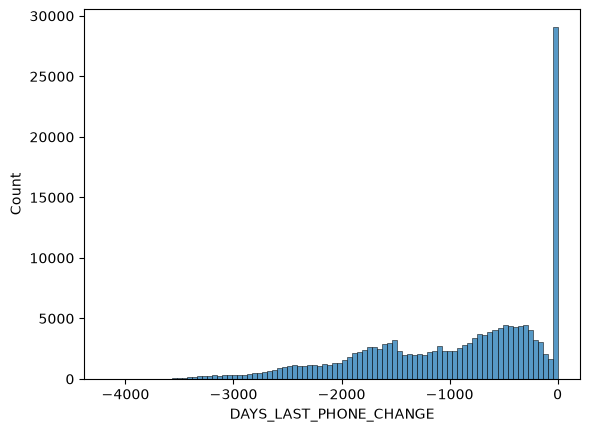

In [23]:
sns.histplot(data = train, x = "DAYS_LAST_PHONE_CHANGE")
plt.show()

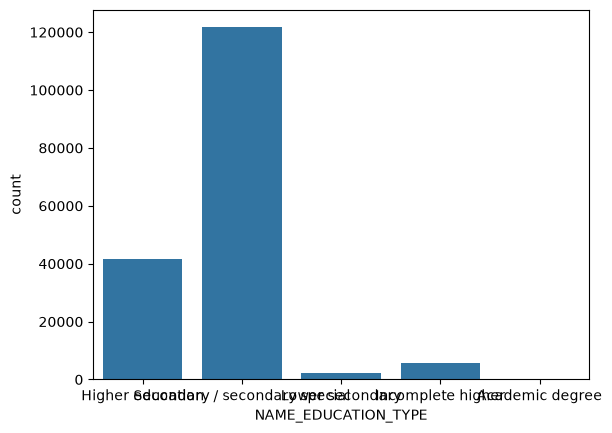

In [24]:
sns.countplot(data = train, x = "NAME_EDUCATION_TYPE")
plt.show()

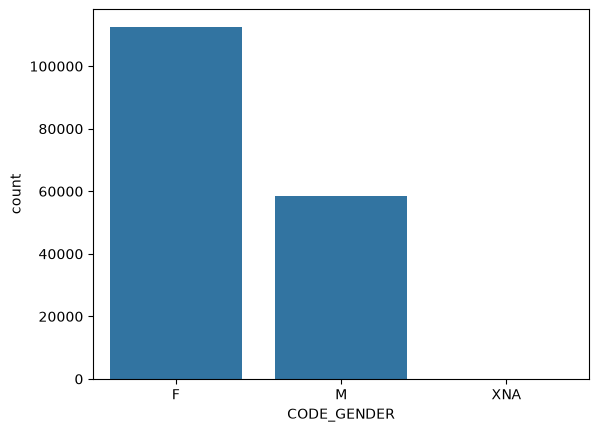

In [25]:
sns.countplot(data = train, x = "CODE_GENDER")
plt.show()

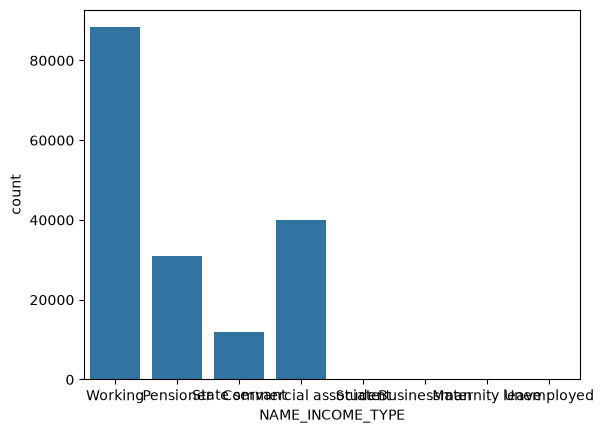

In [27]:
sns.countplot(data = train, x = "NAME_INCOME_TYPE")
plt.show()

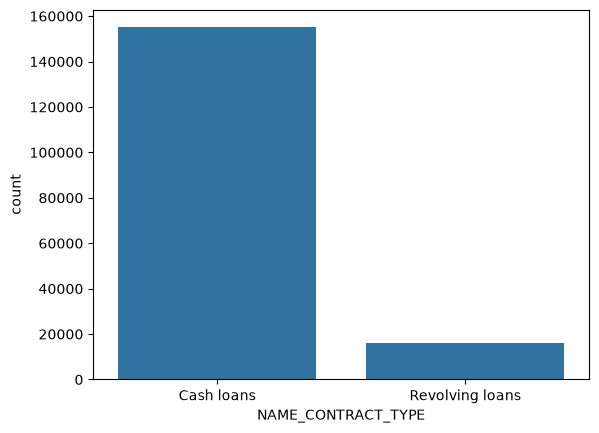

In [28]:
sns.countplot(data = train, x = "NAME_CONTRACT_TYPE")
plt.show()

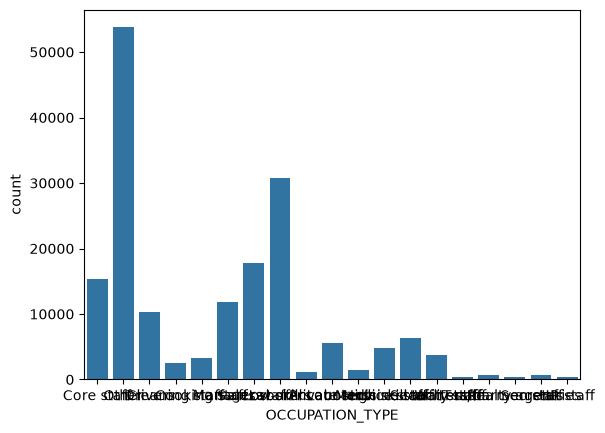

In [29]:
sns.countplot(data = train, x = "OCCUPATION_TYPE")
plt.show()

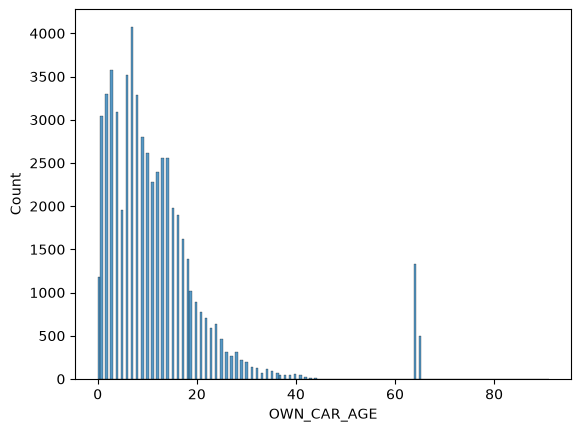

In [30]:
sns.histplot(data = train, x = "OWN_CAR_AGE")
plt.show()

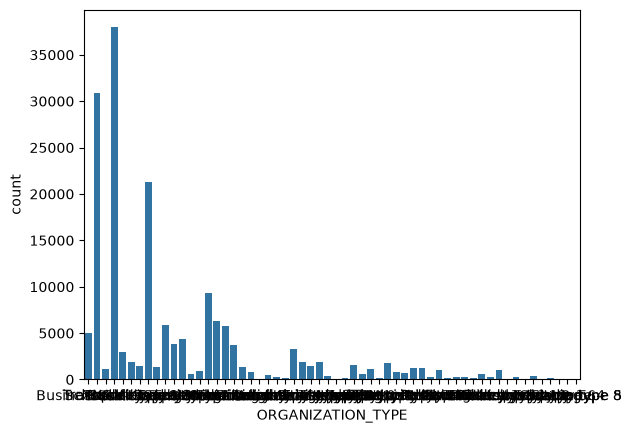

In [31]:
sns.countplot(data = train, x = "ORGANIZATION_TYPE")
plt.show()

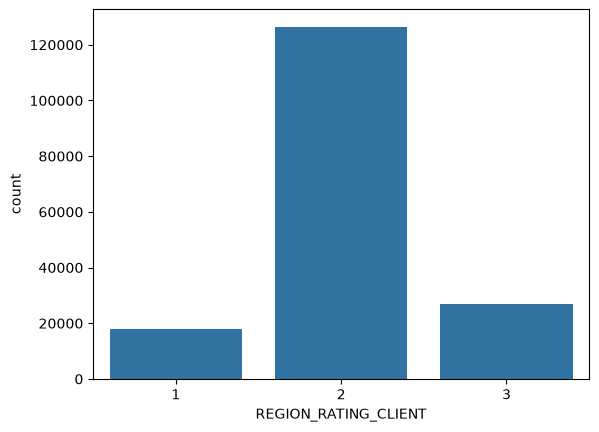

In [33]:
sns.countplot(data = train, x = "REGION_RATING_CLIENT")
plt.show()